# Flow Matching（ICLR 2023）：从解析速度场到多模态生成

这个 notebook 完整实现核心实验 1–13，不包含实验 14（ODE/SDE 同边缘对照）和实验 15（自动驾驶条件轨迹规划）。

| 阶段 | 实验 |
|---|---|
| 解析验证 | 1 条件线性路径；2 高斯边缘协方差；3 解析边缘速度；4 边缘 ODE 曲线；5 后验平均；6 FM/CFM 梯度等价；7 Score–Velocity 恒等式 |
| 神经网络 | 8 八模态数据；9 CFM 训练；10 解析速度验收；11 速度场可视化；12 ODE 求解器比较；13 边缘 ODE 演化 |

> 运行环境：`conda activate pytorch`。随机种子固定为 42，可直接“全部运行”。

## 实验 1：条件线性路径

给定初始分布 $p_0$ 和数据分布 $q$，希望学习速度场 $v_\theta(x,t)$，使 ODE

$$
\frac{dX_t}{dt}=v_\theta(X_t,t),\qquad X_0\sim p_0
$$

在 $t=1$ 将样本运输到 $q$。

边缘 Flow Matching 目标需要真实边缘速度 $u_t(x)$：

$$
\mathcal L_{\mathrm{FM}}
=\mathbb E\|v_\theta(X_t,t)-u_t(X_t)\|^2.
$$

CFM 改用易采样的条件路径。对独立的 $Z\sim p_0$、$Y\sim q$，采用线性 OT 条件路径

$$
X_t=(1-t)Z+tY,\qquad U=Y-Z,
$$

并训练

$$
\mathcal L_{\mathrm{CFM}}
=\mathbb E\|v_\theta(X_t,t)-(Y-Z)\|^2.
$$

平方损失的最优预测是 $\mathbb E[U\mid X_t=x,t]$，它正是边缘速度场。

In [1]:
from pathlib import Path
import math
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if DEVICE.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

OUTPUT_DIR = Path("flow_matching_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

TRAIN_STEPS = 6_000
BATCH_SIZE = 1_024
N_SAMPLES = 3_500

print(f"PyTorch: {torch.__version__}")
print(f"Device: {DEVICE}")
print(f"Output directory: {OUTPUT_DIR.resolve()}")

PyTorch: 2.5.1
Device: cuda
Output directory: /home/zhangjinrui/my_program_code/Data_Processing/python/E2E/DLP/Diffuison/flow_matching_outputs


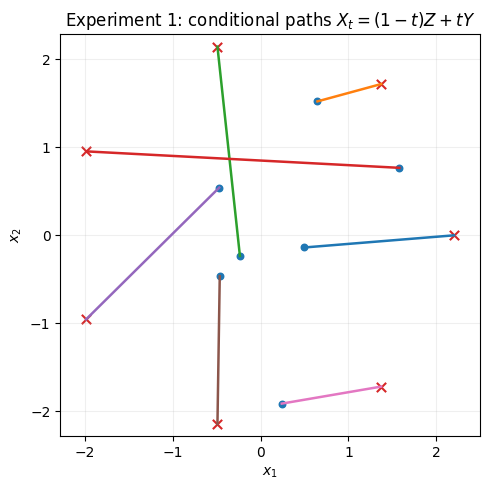

Each paired conditional path is a straight line.


In [2]:
# 随机画出若干条件路径。对每个固定配对 (Z, Y)，X_t 都是直线。
z_demo = np.random.randn(7, 2)
angles_demo = np.arange(7)*2*np.pi/7
y_demo = 2.2*np.stack([np.cos(angles_demo), np.sin(angles_demo)], axis=1)
t_demo = np.linspace(0, 1, 80)

plt.figure(figsize=(5, 5))
for z_i, y_i in zip(z_demo, y_demo):
    path = (1-t_demo[:, None])*z_i+t_demo[:, None]*y_i
    plt.plot(path[:, 0], path[:, 1], lw=1.8)
    plt.scatter(*z_i, c="tab:blue", s=22)
    plt.scatter(*y_i, c="tab:red", marker="x", s=45)
plt.title(r"Experiment 1: conditional paths $X_t=(1-t)Z+tY$")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.axis("equal")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"00_conditional_paths.png", dpi=160, bbox_inches="tight")
plt.show()
print("Each paired conditional path is a straight line.")

## 实验 2–4：解析高斯边缘

### 实验 2：高斯边缘协方差

设

$$
Z\sim\mathcal N(0,I),\qquad
Y\sim\mathcal N(0,\Sigma),\qquad
\Sigma=\operatorname{diag}(4,1),
$$

且 $Z,Y$ 独立。条件路径 $X_t=(1-t)Z+tY$ 对每个配对样本都是直线，但边缘分布为

$$
p_t=\mathcal N(0,C_t),\qquad
C_t=(1-t)^2I+t^2\Sigma.
$$

边缘速度为

$$
u_t(x)=[t\Sigma-(1-t)I]C_t^{-1}x.
$$

写成两个坐标：

$$
u_{t,1}(x)=\frac{5t-1}{(1-t)^2+4t^2}x_1,
\qquad
u_{t,2}(x)=\frac{2t-1}{(1-t)^2+t^2}x_2.
$$

### 实验 3：解析边缘速度

上式给出任意位置的真实边缘速度，下面同时画出固定点 $(1,1)$ 随时间变化的两个速度分量。

### 实验 4：边缘 ODE 曲线

对应边缘 ODE 解为 $X_t=C_t^{1/2}X_0$，通常是弯曲轨迹，而不是某一条条件直线。三个子图依次对应实验 2、3、4。

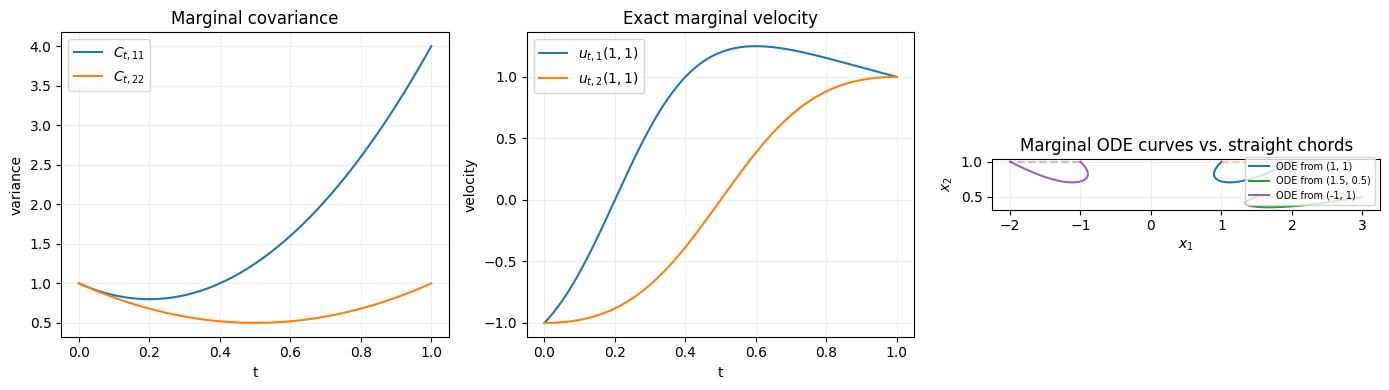

In [3]:
t_grid = np.linspace(0, 1, 301)
c1 = (1-t_grid)**2+4*t_grid**2
c2 = (1-t_grid)**2+t_grid**2
u1_at_one = (5*t_grid-1)/c1
u2_at_one = (2*t_grid-1)/c2

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].plot(t_grid, c1, label=r"$C_{t,11}$")
axes[0].plot(t_grid, c2, label=r"$C_{t,22}$")
axes[0].set(xlabel="t", ylabel="variance", title="Marginal covariance")
axes[0].legend()

axes[1].plot(t_grid, u1_at_one, label=r"$u_{t,1}(1,1)$")
axes[1].plot(t_grid, u2_at_one, label=r"$u_{t,2}(1,1)$")
axes[1].set(xlabel="t", ylabel="velocity", title="Exact marginal velocity")
axes[1].legend()

for a, b in [(1, 1), (1.5, 0.5), (-1, 1)]:
    axes[2].plot(np.sqrt(c1)*a, np.sqrt(c2)*b, label=f"ODE from ({a}, {b})")
    axes[2].plot([a, 2*a], [b, b], "--", alpha=0.35)
axes[2].set(title="Marginal ODE curves vs. straight chords", xlabel="$x_1$", ylabel="$x_2$")
axes[2].set_aspect("equal")
axes[2].legend(fontsize=7)
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"01_analytic_gaussian.png", dpi=160, bbox_inches="tight")
plt.show()

### 双尖峰目标：边际概率路径的解析式与分流轨迹

单高斯只会改变椭圆的尺度，下面改用具有两个尖峰的目标分布。令

$$
Z\sim\mathcal N(0,I),\qquad
Y\sim\frac12\mathcal N(\mu_-,\sigma^2I)
+\frac12\mathcal N(\mu_+,\sigma^2I),
$$

其中 $\mu_-=(-2,0)^\top$、$\mu_+=(2,0)^\top$、$\sigma=0.18$。仍采用条件直线路径

$$
X_t=(1-t)Z+tY.
$$

固定一对 $(z,y)$ 后，条件样本以恒定速度 $y-z$ 沿直线运动。但把配对变量积分掉以后，边际概率路径是解析的双高斯混合：

$$
p_t(x)=\frac12\sum_{k\in\{-,+\}}
\mathcal N\!\left(x;t\mu_k,s_t^2I\right),
\qquad
s_t^2=(1-t)^2+t^2\sigma^2.
$$

它从一个标准高斯逐渐分裂为两个尖峰。记每个分量在位置 $x$ 处的后验责任为

$$
r_k(x,t)=
\frac{\exp\!\left(-\|x-t\mu_k\|^2/(2s_t^2)\right)}
{\sum_j\exp\!\left(-\|x-t\mu_j\|^2/(2s_t^2)\right)}.
$$

给定分量 $k$ 的边缘速度以及混合后的边缘速度都有解析式：

$$
u_t^{(k)}(x)=\mu_k+
\frac{t\sigma^2-(1-t)}{s_t^2}(x-t\mu_k),
$$

$$
u_t(x)=\sum_k r_k(x,t)u_t^{(k)}(x).
$$

因此 $\dot x=u_t(x)$ 的积分曲线会根据当前位置逐渐向左右两个峰分流，通常是弯曲的。条件直线依赖随机抽到的终点 $y$；边缘 ODE 轨迹由当前位置和时间唯一决定，并在总体上产生同一个解析边际密度 $p_t$。

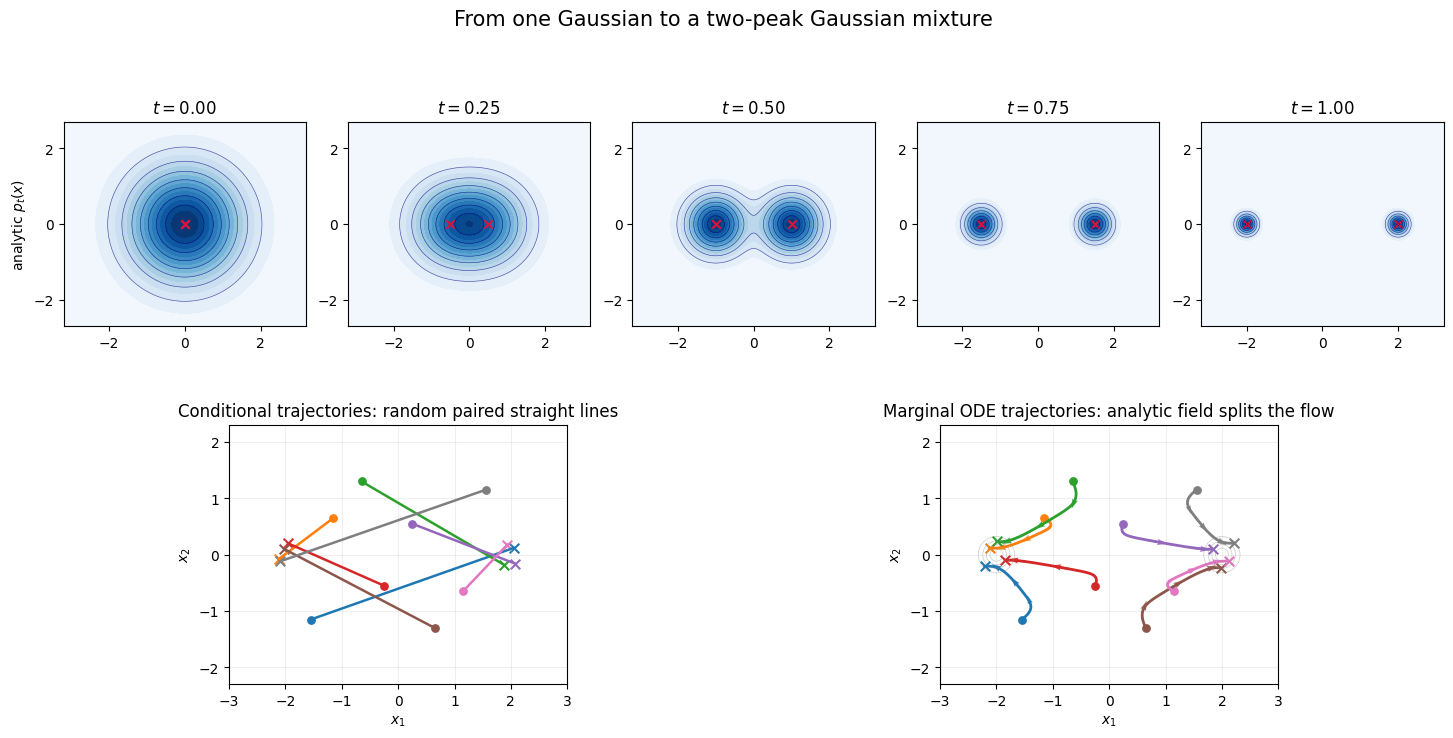

left/right mass = 0.5056 / 0.4944
generated peak centers: [[-1.997e+00 -1.000e-03]
 [ 1.999e+00  1.900e-03]]
target peak centers:    [[-2.  0.]
 [ 2.  0.]]


In [4]:
# 双尖峰高斯混合：解析边际密度、解析边缘速度和对应 ODE 轨迹。
from matplotlib.gridspec import GridSpec

BIMODAL_MEANS = np.array([[-2.0, 0.0], [2.0, 0.0]])
BIMODAL_STD = 0.18


def bimodal_variance(t):
    return (1-t)**2+(t*BIMODAL_STD)**2


def bimodal_density_np(points, t):
    # 解析边际密度 p_t(x)，points 的形状为 (..., 2)。
    variance = bimodal_variance(t)
    delta = points[..., None, :]-t*BIMODAL_MEANS
    component_density = np.exp(-0.5*np.sum(delta**2, axis=-1)/variance)/(2*np.pi*variance)
    return component_density.mean(axis=-1)


def bimodal_velocity_np(points, t):
    # 解析边缘速度 u_t(x)=sum_k r_k(x,t) u_t^(k)(x)。
    points = np.asarray(points)
    variance = bimodal_variance(t)
    delta = points[..., None, :]-t*BIMODAL_MEANS
    logits = -0.5*np.sum(delta**2, axis=-1)/variance
    logits = logits-logits.max(axis=-1, keepdims=True)
    responsibilities = np.exp(logits)
    responsibilities /= responsibilities.sum(axis=-1, keepdims=True)
    ratio = (t*BIMODAL_STD**2-(1-t))/variance
    component_velocity = BIMODAL_MEANS+ratio*delta
    return np.sum(responsibilities[..., None]*component_velocity, axis=-2)


def integrate_bimodal_ode(initial_points, steps=240, keep_path=True):
    # 用 RK4 积分解析边缘速度场。
    x = np.asarray(initial_points, dtype=np.float64).copy()
    h = 1.0/steps
    path = [x.copy()] if keep_path else None
    for step in range(steps):
        t = step*h
        k1 = bimodal_velocity_np(x, t)
        k2 = bimodal_velocity_np(x+0.5*h*k1, t+0.5*h)
        k3 = bimodal_velocity_np(x+0.5*h*k2, t+0.5*h)
        k4 = bimodal_velocity_np(x+h*k3, t+h)
        x += h*(k1+2*k2+2*k3+k4)/6
        if keep_path:
            path.append(x.copy())
    return x, None if path is None else np.stack(path)


snapshot_times = [0.0, 0.25, 0.5, 0.75, 1.0]
grid = np.linspace(-3.5, 3.5, 260)
gx, gy = np.meshgrid(grid, grid)
grid_points = np.stack([gx, gy], axis=-1)

fig = plt.figure(figsize=(15, 7.5))
gs = GridSpec(2, 10, figure=fig, height_ratios=[1.0, 1.18], hspace=0.38, wspace=0.42)

for j, t_value in enumerate(snapshot_times):
    ax = fig.add_subplot(gs[0, 2*j:2*j+2])
    density = bimodal_density_np(grid_points, t_value)
    ax.contourf(gx, gy, density, levels=16, cmap="Blues")
    ax.contour(gx, gy, density, levels=7, colors="navy", linewidths=0.45, alpha=0.65)
    ax.scatter(*(t_value*BIMODAL_MEANS).T, c="crimson", marker="x", s=36)
    ax.set(title=rf"$t={t_value:.2f}$", xlim=(-3.2, 3.2), ylim=(-2.7, 2.7))
    ax.set_aspect("equal")
    ax.set_xticks([-2, 0, 2])
    ax.set_yticks([-2, 0, 2])
    if j == 0:
        ax.set_ylabel(r"analytic $p_t(x)$")

# 固定例子使图可复现。条件路径的左右终点与起点位置没有确定关系。
z_cond = np.array([
    [-1.55, -1.15], [-1.15, 0.65], [-0.65, 1.30], [-0.25, -0.55],
    [0.25, 0.55], [0.65, -1.30], [1.15, -0.65], [1.55, 1.15],
])
y_cond = np.array([
    [2.05, 0.12], [-2.12, -0.08], [1.88, -0.18], [-1.95, 0.20],
    [2.08, -0.16], [-2.02, 0.10], [1.94, 0.18], [-2.10, -0.12],
])
t_line = np.linspace(0, 1, 121)
colors = plt.cm.tab10(np.arange(len(z_cond)))

ax_cond = fig.add_subplot(gs[1, :5])
for color, z_i, y_i in zip(colors, z_cond, y_cond):
    conditional_path = (1-t_line[:, None])*z_i+t_line[:, None]*y_i
    ax_cond.plot(conditional_path[:, 0], conditional_path[:, 1], color=color, lw=1.8)
    ax_cond.scatter(*z_i, color=color, marker="o", s=28)
    ax_cond.scatter(*y_i, color=color, marker="x", s=48)

# 从相同的一组初始点出发，积分解析边缘速度场。
_, marginal_paths = integrate_bimodal_ode(z_cond, steps=240, keep_path=True)
ax_marg = fig.add_subplot(gs[1, 5:])
for i, color in enumerate(colors):
    path_i = marginal_paths[:, i]
    ax_marg.plot(path_i[:, 0], path_i[:, 1], color=color, lw=2.0)
    ax_marg.scatter(*path_i[0], color=color, marker="o", s=28)
    ax_marg.scatter(*path_i[-1], color=color, marker="x", s=48)
    for idx in [60, 130, 200]:
        tv = idx/240
        velocity = bimodal_velocity_np(path_i[idx:idx+1], tv)[0]
        ax_marg.quiver(path_i[idx, 0], path_i[idx, 1], velocity[0], velocity[1],
                       color=color, angles="xy", scale_units="xy", scale=8,
                       width=0.006, alpha=0.9)

# 淡色终点密度提示两条边缘 ODE 轨迹束最终覆盖的目标分布。
target_density = bimodal_density_np(grid_points, 1.0)
ax_marg.contour(gx, gy, target_density, levels=5, colors="gray", linewidths=0.6, alpha=0.35)

ax_cond.set_title("Conditional trajectories: random paired straight lines")
ax_marg.set_title("Marginal ODE trajectories: analytic field splits the flow")
for ax in (ax_cond, ax_marg):
    ax.set(xlabel="$x_1$", ylabel="$x_2$", xlim=(-3.0, 3.0), ylim=(-2.3, 2.3))
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

fig.suptitle("From one Gaussian to a two-peak Gaussian mixture", fontsize=15)
fig.subplots_adjust(top=0.84, bottom=0.08, left=0.06, right=0.98)
fig.savefig(OUTPUT_DIR/"01b_bimodal_marginal_probability_path.png", dpi=170, bbox_inches="tight")
plt.show()

# 检查解析速度确实把标准高斯分成左右两支。
rng = np.random.default_rng(SEED)
validation_initial = rng.standard_normal((30_000, 2))
validation_final, _ = integrate_bimodal_ode(validation_initial, steps=160, keep_path=False)
left_fraction = np.mean(validation_final[:, 0] < 0)
left_center = validation_final[validation_final[:, 0] < 0].mean(axis=0)
right_center = validation_final[validation_final[:, 0] >= 0].mean(axis=0)
print(f"left/right mass = {left_fraction:.4f} / {1-left_fraction:.4f}")
print("generated peak centers:", np.round(np.stack([left_center, right_center]), 4))
print("target peak centers:   ", BIMODAL_MEANS)

## 实验 5：后验平均

CFM 的条件速度为 $U=Y-Z$。边缘速度满足

$$
u_t(x)=\mathbb E[Y-Z\mid X_t=x].
$$

下面在固定 $t=0.4$、$x=(0.5,0.5)$ 处进行大样本 Monte Carlo，用高斯核近似条件期望，并与上面的解析速度比较。

In [5]:
@torch.no_grad()
def posterior_average_experiment(n=500_000, t_value=0.4, target=(0.5, 0.5), bandwidth=0.18):
    z = torch.randn(n, 2, device=DEVICE)
    y = torch.randn(n, 2, device=DEVICE)*torch.tensor([2.0, 1.0], device=DEVICE)
    x = (1-t_value)*z+t_value*y
    target_t = torch.tensor(target, device=DEVICE)
    kernel_weight = torch.exp(-(x-target_t).square().sum(1)/(2*bandwidth**2))
    estimate = (kernel_weight[:, None]*(y-z)).sum(0)/kernel_weight.sum()
    covariance = torch.tensor([
        (1-t_value)**2+4*t_value**2,
        (1-t_value)**2+t_value**2,
    ], device=DEVICE)
    exact = (
        torch.tensor([5*t_value-1, 2*t_value-1], device=DEVICE)
        /covariance*target_t
    )
    effective_n = kernel_weight.sum().square()/kernel_weight.square().sum()
    return estimate.cpu().numpy(), exact.cpu().numpy(), effective_n.item()


posterior_estimate, exact_velocity, effective_n = posterior_average_experiment()
print("Kernel posterior estimate:", np.round(posterior_estimate, 5))
print("Exact marginal velocity:   ", np.round(exact_velocity, 5))
print("Absolute error:            ", np.round(np.abs(posterior_estimate-exact_velocity), 5))
print(f"Effective kernel sample size: {effective_n:.1f}")

Kernel posterior estimate: [ 0.48214 -0.18052]
Exact marginal velocity:    [ 0.5     -0.19231]
Absolute error:             [0.01786 0.01179]
Effective kernel sample size: 29684.5


## 实验 6：FM 与 CFM 的梯度等价

在一维例子中令 $Y,Z\sim\mathcal N(0,1)$、$X_t=(1-t)Z+tY$。此时

$$
c_t=(1-t)^2+t^2,\qquad
u_t(x)=\frac{2t-1}{c_t}x.
$$

对线性模型 $v_\theta(x,t)=\theta x$，分别用条件标签 $Y-Z$ 和边缘标签 $u_t(X_t)$ 计算梯度。两个 loss 的值相差一个与 $\theta$ 无关的常数，但梯度应一致。

In [6]:
@torch.no_grad()
def gradient_equivalence_experiment(n=1_000_000, t_value=0.3, theta=0.8):
    y = torch.randn(n, device=DEVICE)
    z = torch.randn(n, device=DEVICE)
    x = (1-t_value)*z+t_value*y
    conditional_target = y-z
    c_t = (1-t_value)**2+t_value**2
    coefficient = (2*t_value-1)/c_t
    marginal_target = coefficient*x

    cfm_gradient = 2*((theta*x-conditional_target)*x).mean()
    fm_gradient = 2*((theta*x-marginal_target)*x).mean()
    theoretical_gradient = 2*c_t*(theta-coefficient)
    cfm_loss = (theta*x-conditional_target).square().mean()
    fm_loss = (theta*x-marginal_target).square().mean()
    return np.array([
        cfm_gradient.item(), fm_gradient.item(), theoretical_gradient,
        cfm_loss.item(), fm_loss.item(),
    ])


gradient_metrics = gradient_equivalence_experiment()
print(f"CFM gradient:         {gradient_metrics[0]:.6f}")
print(f"FM gradient:          {gradient_metrics[1]:.6f}")
print(f"Theoretical gradient: {gradient_metrics[2]:.6f}")
print(f"CFM loss:             {gradient_metrics[3]:.6f}")
print(f"FM loss:              {gradient_metrics[4]:.6f}")
print(f"Gradient difference:  {abs(gradient_metrics[0]-gradient_metrics[1]):.6f}")

CFM gradient:         1.727688
FM gradient:          1.729196
Theoretical gradient: 1.728000
CFM loss:             3.009740
FM loss:              1.287953
Gradient difference:  0.001508


## 实验 7：Score 与 Velocity 恒等式

同一个一维高斯路径的边缘 Score 是 $s_t(x)=-x/c_t$。由线性路径关系可以从边缘速度恢复 Score：

$$
s_t(x)=\frac{t\,u_t(x)-x}{1-t}.
$$

这个实验验证 Flow Matching 的速度参数化与扩散模型的 Score 参数化描述同一概率路径时可以互相转换。

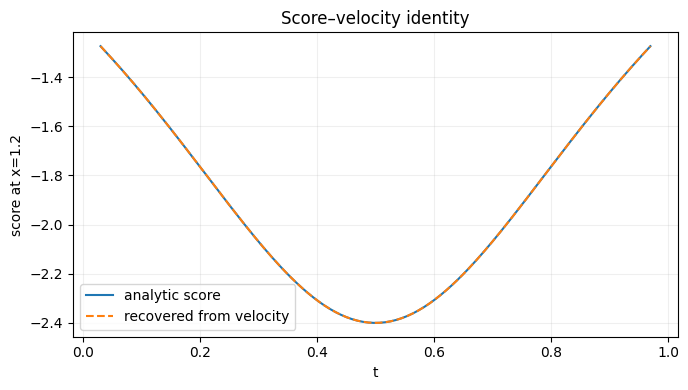

Maximum absolute identity error: 3.331e-15


In [7]:
t_score = np.linspace(0.03, 0.97, 200)
x_fixed = 1.2
c_score = (1-t_score)**2+t_score**2
analytic_score = -x_fixed/c_score
analytic_velocity = (2*t_score-1)*x_fixed/c_score
score_from_velocity = (t_score*analytic_velocity-x_fixed)/(1-t_score)
score_identity_error = np.max(np.abs(analytic_score-score_from_velocity))

plt.figure(figsize=(7, 4))
plt.plot(t_score, analytic_score, label="analytic score")
plt.plot(t_score, score_from_velocity, "--", label="recovered from velocity")
plt.xlabel("t")
plt.ylabel("score at x=1.2")
plt.title("Score–velocity identity")
plt.grid(alpha=0.2)
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR/"02_score_velocity_identity.png", dpi=160, bbox_inches="tight")
plt.show()
print(f"Maximum absolute identity error: {score_identity_error:.3e}")

## 实验 8：八模态 CFM 训练数据

目标分布是圆周上的八个窄高斯分量：半径 2.2，分量标准差 0.16。初始分布为标准二维高斯。

每个训练样本只需独立采样 $(Z,Y,t)$，然后直接构造

$$
X_t=(1-t)Z+tY,\qquad U=Y-Z.
$$

整个训练过程不需要模拟 ODE，也不需要显式计算边缘概率密度。这就是 Flow Matching 的 simulation-free training。

In [8]:
DIM = 2
NUM_MODES = 8
RADIUS = 2.2
DATA_STD = 0.16
angles = torch.arange(NUM_MODES, device=DEVICE)*2*math.pi/NUM_MODES
CENTERS = RADIUS*torch.stack([torch.cos(angles), torch.sin(angles)], dim=1)
WEIGHTS = torch.full((NUM_MODES,), 1/NUM_MODES, device=DEVICE)


def sample_mixture(n):
    labels = torch.multinomial(WEIGHTS, n, replacement=True)
    return CENTERS[labels]+DATA_STD*torch.randn(n, DIM, device=DEVICE)


with torch.no_grad():
    target_check = sample_mixture(20_000)
    assignment = torch.cdist(target_check, CENTERS).argmin(dim=1)
    empirical_weights = torch.bincount(assignment, minlength=NUM_MODES).float()/len(assignment)
print("Empirical target weights:", empirical_weights.cpu().numpy().round(3))

Empirical target weights: [0.126 0.128 0.129 0.126 0.126 0.122 0.121 0.122]


## 实验 9：速度网络与 CFM 训练

网络输入二维状态和连续时间，输出二维速度。为了让时间条件更容易学习，使用正弦时间编码；训练监督仍然只是 $Y-Z$。

In [9]:
class VelocityNet(nn.Module):
    def __init__(self, hidden=128, time_dim=32):
        super().__init__()
        self.time_dim = time_dim
        self.net = nn.Sequential(
            nn.Linear(DIM+time_dim, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, DIM),
        )

    def time_embedding(self, t):
        frequencies = 2.0**torch.arange(self.time_dim//2, device=t.device, dtype=t.dtype)
        phase = 2*math.pi*t*frequencies[None, :]
        return torch.cat([torch.sin(phase), torch.cos(phase)], dim=1)

    def forward(self, x, t):
        if t.ndim == 0:
            t = t.expand(len(x), 1)
        elif t.ndim == 1:
            t = t[:, None]
        return self.net(torch.cat([x, self.time_embedding(t)], dim=1))


model = VelocityNet().to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
print(model)
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

VelocityNet(
  (net): Sequential(
    (0): Linear(in_features=34, out_features=128, bias=True)
    (1): SiLU()
    (2): Linear(in_features=128, out_features=128, bias=True)
    (3): SiLU()
    (4): Linear(in_features=128, out_features=128, bias=True)
    (5): SiLU()
    (6): Linear(in_features=128, out_features=2, bias=True)
  )
)
Trainable parameters: 37,762


In [10]:
losses = []
model.train()
training_started = time.perf_counter()
for step in range(1, TRAIN_STEPS+1):
    y = sample_mixture(BATCH_SIZE)
    z = torch.randn_like(y)
    t = torch.rand(BATCH_SIZE, 1, device=DEVICE)
    xt = (1-t)*z+t*y
    target_velocity = y-z
    loss = (model(xt, t)-target_velocity).square().mean()

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()
    losses.append(loss.item())

    if step == 1 or step % 600 == 0:
        print(f"step {step:4d}/{TRAIN_STEPS} | loss(200-step avg)={np.mean(losses[-200:]):.6f}")

print(f"Training finished in {time.perf_counter()-training_started:.1f} s")
torch.save(model.state_dict(), OUTPUT_DIR/"flow_matching_velocity_net.pt")

step    1/6000 | loss(200-step avg)=3.495782


step  600/6000 | loss(200-step avg)=2.222548


step 1200/6000 | loss(200-step avg)=2.150442


step 1800/6000 | loss(200-step avg)=2.095051


step 2400/6000 | loss(200-step avg)=2.080431


...

step 3600/6000 | loss(200-step avg)=2.065578


step 4200/6000 | loss(200-step avg)=2.071788


step 4800/6000 | loss(200-step avg)=2.060652


step 5400/6000 | loss(200-step avg)=2.062655


step 6000/6000 | loss(200-step avg)=2.059286
Training finished in 21.7 s


## 实验 10：解析八模态边缘速度验收

对第 $k$ 个数据分量，线性路径的边缘分量为

$$
X_t\mid k\sim\mathcal N(t\mu_k,c_tI),
\qquad c_t=(1-t)^2+t^2\sigma_{\mathrm{data}}^2.
$$

在该分量内，条件速度的后验均值为

$$
\mathbb E[Y-Z\mid X_t=x,k]
=\mu_k+\frac{t\sigma_{\mathrm{data}}^2-(1-t)}{c_t}(x-t\mu_k).
$$

再按照 $p(k\mid X_t=x)$ 加权，即得到真实边缘速度。它只用于评估，不参与训练。

      t     velocity MSE
   0.05        0.0013622
   0.20        0.0033357
   0.40        0.0051284
   0.60        0.0096649
   0.80        0.0351179
   0.95        0.0089761


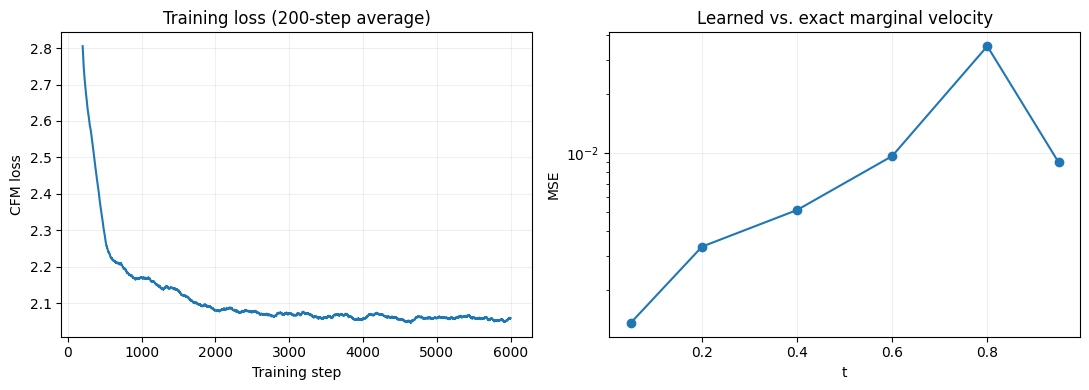

In [11]:
def exact_mixture_velocity(x, t):
    if t.ndim == 0:
        t = t.expand(len(x), 1)
    elif t.ndim == 1:
        t = t[:, None]
    variance = (1-t).square()+t.square()*DATA_STD**2
    means_t = t[:, None, :]*CENTERS[None, :, :]
    delta = x[:, None, :]-means_t
    logits = torch.log(WEIGHTS)[None, :]-delta.square().sum(-1)/(2*variance)
    responsibilities = torch.softmax(logits, dim=1)
    covariance_ratio = (t*DATA_STD**2-(1-t))/variance
    component_velocity = CENTERS[None, :, :]+covariance_ratio[:, None, :]*delta
    return (responsibilities[:, :, None]*component_velocity).sum(dim=1)


@torch.no_grad()
def evaluate_velocity(n=10_000):
    model.eval()
    rows = []
    for t_value in [0.05, 0.2, 0.4, 0.6, 0.8, 0.95]:
        t = torch.full((n, 1), t_value, device=DEVICE)
        z = torch.randn(n, DIM, device=DEVICE)
        y = sample_mixture(n)
        xt = (1-t)*z+t*y
        mse = (model(xt, t)-exact_mixture_velocity(xt, t)).square().mean().item()
        rows.append((t_value, mse))
    return np.asarray(rows)


velocity_metrics = evaluate_velocity()
print(f"{'t':>7} {'velocity MSE':>16}")
for t_value, mse in velocity_metrics:
    print(f"{t_value:7.2f} {mse:16.7f}")

window = 200
loss_smooth = np.convolve(losses, np.ones(window)/window, mode="valid")
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(np.arange(window, len(losses)+1), loss_smooth)
axes[0].set(xlabel="Training step", ylabel="CFM loss", title=f"Training loss ({window}-step average)")
axes[1].semilogy(velocity_metrics[:, 0], velocity_metrics[:, 1], "o-")
axes[1].set(xlabel="t", ylabel="MSE", title="Learned vs. exact marginal velocity")
for ax in axes:
    ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"03_training_and_velocity_error.png", dpi=160, bbox_inches="tight")
plt.show()

## 实验 11：解析与学习速度场可视化

在 $t=0.5$ 的同一网格上画出解析边缘速度与网络预测。红色叉号是当前时刻各高斯分量的均值 $t\mu_k$；两个箭头场的方向和大小应基本一致。

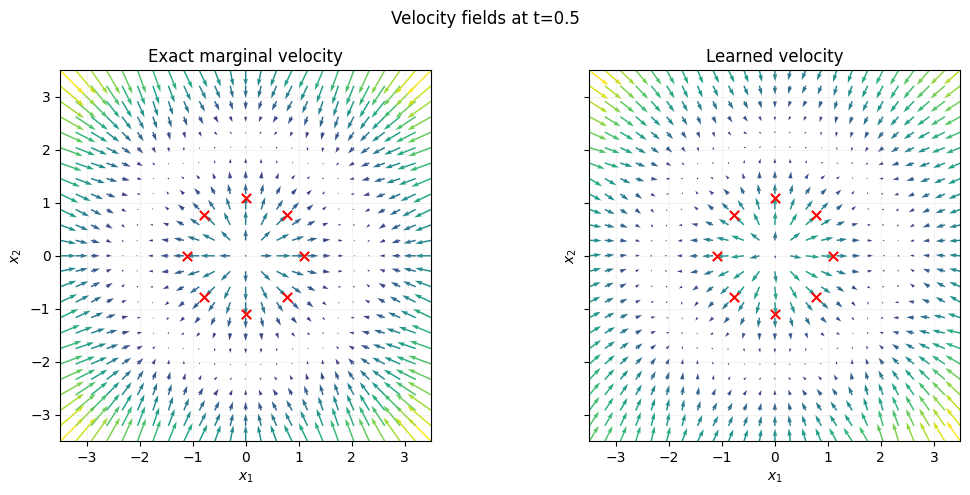

In [12]:
@torch.no_grad()
def plot_velocity_fields(t_value=0.5):
    axis = torch.linspace(-3.5, 3.5, 25, device=DEVICE)
    yy, xx = torch.meshgrid(axis, axis, indexing="ij")
    points = torch.stack([xx.ravel(), yy.ravel()], dim=1)
    t = torch.full((len(points), 1), t_value, device=DEVICE)
    fields = [exact_mixture_velocity(points, t), model(points, t)]
    titles = ["Exact marginal velocity", "Learned velocity"]
    p = points.cpu().numpy()

    fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
    for ax, field, title in zip(axes, fields, titles):
        f = field.cpu().numpy()
        magnitude = np.linalg.norm(f, axis=1)
        ax.quiver(p[:, 0], p[:, 1], f[:, 0], f[:, 1], magnitude,
                  cmap="viridis", angles="xy", scale_units="xy", scale=8, width=0.004)
        current_centers = (t_value*CENTERS).cpu().numpy()
        ax.scatter(current_centers[:, 0], current_centers[:, 1], c="red", marker="x", s=45)
        ax.set(title=title, xlabel="$x_1$", ylabel="$x_2$", xlim=(-3.5, 3.5), ylim=(-3.5, 3.5))
        ax.set_aspect("equal")
        ax.grid(alpha=0.15)
    fig.suptitle(f"Velocity fields at t={t_value}")
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR/"04_velocity_fields.png", dpi=160, bbox_inches="tight")
    plt.show()


plot_velocity_fields()

## 实验 12：ODE 生成与求解器比较

训练完成后从 $X_0\sim\mathcal N(0,I)$ 出发，对学习 ODE 积分到 $t=1$。

Euler：

$$
X_{k+1}=X_k+h\,v_\theta(X_k,t_k).
$$

Midpoint（二阶 Runge–Kutta）：

$$
k_1=v_\theta(X_k,t_k),\qquad
k_2=v_\theta(X_k+\tfrac h2k_1,t_k+\tfrac h2),
$$

$$
X_{k+1}=X_k+h k_2.
$$

一步 Euler 等价于用初始速度近似整条轨迹，通常不足以恢复复杂多模态分布。

In [13]:
@torch.no_grad()
def ode_sample(initial, steps, method="euler", keep_stages=False):
    x = initial.clone()
    h = 1.0/steps
    snapshots = {0: x.cpu().numpy().copy()}
    nfe = 0
    for k in range(steps):
        t = torch.full((len(x), 1), k*h, device=DEVICE)
        if method == "euler":
            x = x+h*model(x, t)
            nfe += 1
        elif method == "midpoint":
            k1 = model(x, t)
            k2 = model(x+0.5*h*k1, t+0.5*h)
            x = x+h*k2
            nfe += 2
        else:
            raise ValueError("method must be 'euler' or 'midpoint'")
        if keep_stages and k+1 in {steps//4, steps//2, 3*steps//4, steps}:
            snapshots[k+1] = x.cpu().numpy().copy()
    return x.cpu().numpy(), snapshots, nfe


initial_noise = torch.randn(N_SAMPLES, DIM, device=DEVICE)
sampler_configs = [("Euler 1", 1, "euler"), ("Euler 4", 4, "euler"),
                   ("Euler 20", 20, "euler"), ("Midpoint 10", 10, "midpoint")]
generated = {}
sampling_started = time.perf_counter()
for name, steps, method in sampler_configs:
    generated[name], _, _ = ode_sample(initial_noise, steps, method)
with torch.no_grad():
    real = sample_mixture(N_SAMPLES).cpu().numpy()
print(f"All ODE samplers finished in {time.perf_counter()-sampling_started:.2f} s")

All ODE samplers finished in 0.03 s


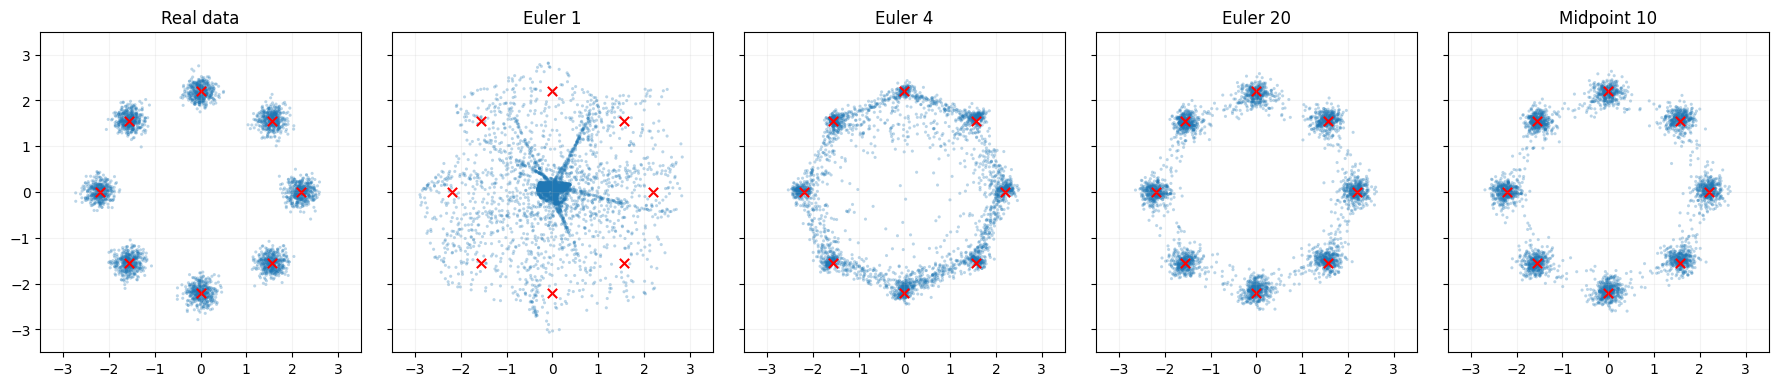

sampler         modes    max |w-1/8|   center err   avg std
Real data           8         0.0059       0.0108    0.1610
Euler 1             8         0.0493       1.1974    0.5928
Euler 4             8         0.0284       0.1398    0.2669
Euler 20            8         0.0116       0.0500    0.1817
Midpoint 10         8         0.0119       0.0381    0.1753


In [14]:
def scatter(ax, points, title):
    ax.scatter(points[:, 0], points[:, 1], s=5, alpha=0.3, edgecolors="none")
    ax.scatter(CENTERS[:, 0].cpu(), CENTERS[:, 1].cpu(), c="red", marker="x", s=45)
    ax.set(title=title, xlim=(-3.5, 3.5), ylim=(-3.5, 3.5))
    ax.set_aspect("equal")
    ax.grid(alpha=0.15)


fig, axes = plt.subplots(1, 5, figsize=(18, 3.6), sharex=True, sharey=True)
scatter(axes[0], real, "Real data")
for ax, (name, points) in zip(axes[1:], generated.items()):
    scatter(ax, points, name)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"05_generation_solvers.png", dpi=160, bbox_inches="tight")
plt.show()


def mode_metrics(points):
    points_t = torch.as_tensor(points, dtype=torch.float32, device=DEVICE)
    labels = torch.cdist(points_t, CENTERS).argmin(dim=1)
    weights = torch.bincount(labels, minlength=NUM_MODES).float()/len(points_t)
    means = torch.stack([points_t[labels == i].mean(0) for i in range(NUM_MODES)])
    stds = torch.stack([points_t[labels == i].std(0) for i in range(NUM_MODES)])
    modes = int((weights > 0.02).sum())
    max_weight_error = (weights-1/NUM_MODES).abs().max().item()
    center_error = torch.linalg.vector_norm(means-CENTERS, dim=1).mean().item()
    return modes, max_weight_error, center_error, stds.mean().item()


print(f"{'sampler':<14} {'modes':>6} {'max |w-1/8|':>14} {'center err':>12} {'avg std':>9}")
for name, points in [("Real data", real), *generated.items()]:
    modes, weight_error, center_error, avg_std = mode_metrics(points)
    print(f"{name:<14} {modes:6d} {weight_error:14.4f} {center_error:12.4f} {avg_std:9.4f}")

## 实验 13：学习到的边缘 ODE 演化

条件路径中的单个 $(Z,Y)$ 配对沿直线移动，但网络学习的是所有条件速度的后验平均。边缘 ODE 轨迹因此会根据当前位置和时间弯曲、分叉，并最终形成八个模态。

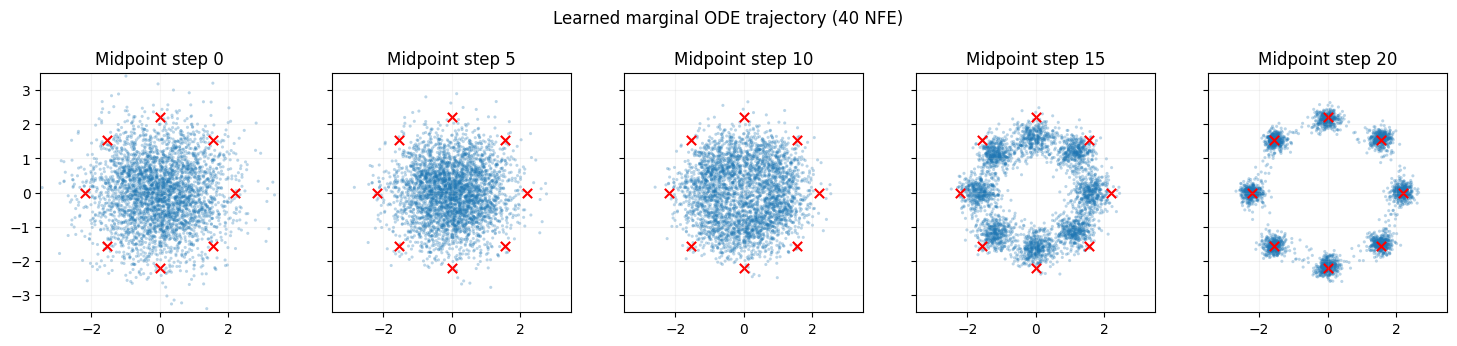

In [15]:
trajectory_samples, trajectory, trajectory_nfe = ode_sample(
    initial_noise, steps=20, method="midpoint", keep_stages=True
)
stage_ids = [0, 5, 10, 15, 20]
fig, axes = plt.subplots(1, 5, figsize=(15, 3.1), sharex=True, sharey=True)
for ax, stage in zip(axes, stage_ids):
    scatter(ax, trajectory[stage], f"Midpoint step {stage}")
fig.suptitle(f"Learned marginal ODE trajectory ({trajectory_nfe} NFE)", y=1.04)
fig.tight_layout()
fig.savefig(OUTPUT_DIR/"06_marginal_ode_trajectory.png", dpi=160, bbox_inches="tight")
plt.show()

## 核心实验结论

| 实验 | 验证内容 |
|---|---|
| 1–4 | 条件路径为直线；边缘协方差、真实速度与弯曲 ODE 轨迹均符合解析式 |
| 5 | $u_t(x)=\mathbb E[U\mid X_t=x,t]$ |
| 6 | CFM 与不可直接获得的 FM 具有相同参数梯度 |
| 7 | Score 与 Velocity 两种参数化可描述同一线性概率路径 |
| 8–9 | CFM 无需模拟训练轨迹即可学习八模态边缘速度 |
| 10–11 | 学习速度可由解析混合高斯边缘速度定量和可视化验收 |
| 12–13 | 多步积分恢复八个模态，并展示完整边缘 ODE 演化过程 |
